# Task 5: Account Security Monitoring EDA

Unsupervised descriptive EDA of the provided unlabeled data. No artificial labels, pseudo-labels, preprocessing fit, or anomaly model is created.

## 1. Dataset Loading

In [6]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
SEED = 342
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid', context='notebook')

# This notebook is stored in notebook/, so the data path remains portable.
DATA_ROOT = Path('../cpe342-kaggle-main')

def quality_report(frame, id_col='player_id'):
    numeric = frame.select_dtypes(include=np.number)
    missing = pd.DataFrame({
        'missing_count': frame.isna().sum(),
        'missing_pct': frame.isna().mean().mul(100)
    }).sort_values('missing_count', ascending=False)
    print(f'Duplicate rows: {frame.duplicated().sum():,}')
    print(f'Duplicate {id_col}s: {frame[id_col].duplicated().sum():,}')
    print(f'Infinite numeric values: {np.isinf(numeric).sum().sum():,}')
    display(missing.query('missing_count > 0'))
    constants = frame.columns[frame.nunique(dropna=False).le(1)].tolist()
    near_constant = (frame.nunique(dropna=False) / len(frame)).sort_values().head(10)
    print('Constant features:', constants or 'None')
    display(near_constant.to_frame('unique_ratio'))
    return missing

def plot_missing(missing, title):
    shown = missing.query('missing_count > 0').head(25)
    if shown.empty:
        print('No missing values to plot.')
        return
    fig, ax = plt.subplots(figsize=(10, max(3, len(shown) * .3)))
    sns.barplot(data=shown.reset_index(), y='index', x='missing_pct', ax=ax, color='#4C72B0')
    ax.set(title=title, xlabel='Missing values (%)', ylabel='Column')
    plt.show(); plt.close()

def strong_correlations(frame, threshold=.75):
    corr = frame.select_dtypes(include=np.number).corr()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    pairs = upper.stack().rename('correlation').reset_index()
    return pairs.loc[pairs.correlation.abs().ge(threshold)].sort_values('correlation', key=np.abs, ascending=False)

DATA_FILE = DATA_ROOT / '05_anomaly_detection/test.csv'
df = pd.read_csv(DATA_FILE)
print('Shape:', df.shape)
print(f'Memory usage: {df.memory_usage(deep=True).sum()/1024**2:.2f} MiB')
display(df.head())
display(df.describe().T)

Shape: (25889, 123)
Memory usage: 24.47 MiB


,player_id,login_count_1,login_count_2,login_count_3,login_count_4,login_lat_1,login_lon_1,login_lat_2,login_lon_2,login_lat_3,login_lon_3,login_lat_4,login_lon_4,location_changes_1,location_changes_2,location_changes_3,location_changes_4,device_count_1,device_count_2,device_count_3,device_count_4,ip_hash_entropy_1,ip_hash_entropy_2,ip_hash_entropy_3,ip_hash_entropy_4,login_time_variance_1,login_time_variance_2,login_time_variance_3,login_time_variance_4,session_duration_mean_1,session_duration_mean_2,session_duration_mean_3,session_duration_mean_4,session_duration_std_1,session_duration_std_2,session_duration_std_3,session_duration_std_4,skill_rating_1,skill_rating_2,skill_rating_3,skill_rating_4,skill_trajectory_1,skill_trajectory_2,skill_trajectory_3,skill_trajectory_4,play_pattern_consistency_1,play_pattern_consistency_2,play_pattern_consistency_3,play_pattern_consistency_4,activity_level_1,...,reaction_time_std_1,reaction_time_std_2,reaction_time_std_3,reaction_time_std_4,performance_stability_1,performance_stability_2,performance_stability_3,performance_stability_4,purchase_frequency_1,purchase_frequency_2,purchase_frequency_3,purchase_frequency_4,purchase_amount_mean_1,purchase_amount_mean_2,purchase_amount_mean_3,purchase_amount_mean_4,purchase_amount_std_1,purchase_amount_std_2,purchase_amount_std_3,purchase_amount_std_4,refund_count_1,refund_count_2,refund_count_3,refund_count_4,currency_transfers_1,currency_transfers_2,currency_transfers_3,currency_transfers_4,friend_adds_1,friend_adds_2,friend_adds_3,friend_adds_4,friend_removes_1,friend_removes_2,friend_removes_3,friend_removes_4,communication_frequency_1,communication_frequency_2,communication_frequency_3,communication_frequency_4,guild_changes_1,guild_changes_2,guild_changes_3,guild_changes_4,account_age_days,behavior_stability,password_changed,vpn_usage,suspicious_login_time,mass_item_sale
0,P005807,90.311349,90.547639,85.696177,85.467099,NaN,-73.275855,39.258196,-73.608702,38.097200,-74.503247,38.326030,-74.113608,0.390271,0.408314,0.325789,0.527446,2.0,2.0,2.0,2.0,0.530087,0.372052,0.461817,0.747281,8.212253,6.752891,4.956936,6.944254,64.082327,53.127890,59.116568,64.053810,11.999764,10.890844,12.232108,11.545234,2255.441271,2302.587900,2179.314328,2303.784502,0.809475,0.662663,NaN,0.640582,0.763557,0.665822,0.771966,0.819300,1.445053,...,42.530776,46.433497,57.186428,52.713709,0.831568,0.834143,0.754986,0.800571,5.551737,4.395928,5.006584,5.137306,509.582034,346.709056,321.426840,408.887934,61.297930,47.105594,62.738594,41.683333,0.0,0.0,1.0,1.0,NaN,NaN,1.562235,1.050113,10.591501,10.704240,6.853613,7.874519,1.982945,2.619925,1.906177,2.310822,0.935336,1.387203,1.334798,1.146139,2.0,2.0,2.0,2.0,363.872386,0.726597,0.0,0.0,0.0,0.0
1,P009995,92.522163,67.906460,113.678435,98.321423,-40.247854,-126.380420,NaN,-126.226320,-39.987100,-126.841525,-39.343639,-125.951100,1.567341,0.975997,1.045117,1.635499,2.0,1.0,3.0,2.0,0.770227,0.720307,NaN,0.302361,4.998366,4.732861,5.123391,5.000709,110.686987,81.107938,78.227890,94.593729,27.296410,25.958254,24.933346,22.985136,1881.086919,1874.039346,1926.204038,2025.575481,-3.943757,-5.119281,-2.677766,-4.161005,NaN,0.678387,0.714970,0.754357,0.697360,...,38.393174,NaN,26.648113,29.828687,0.754905,0.726032,0.756348,0.800667,1.190450,1.885053,1.057608,1.238339,433.859875,452.312030,389.344163,339.212658,182.381148,190.857733,175.509508,169.985182,0.0,-1.0,1.0,0.0,2.617345,2.983249,3.061048,3.118324,14.200669,15.992700,9.972713,12.262340,3.177272,1.958026,2.891784,3.484787,0.441131,0.368956,0.382962,0.449833,0.0,0.0,0.0,1.0,1218.236865,0.774107,0.0,0.0,1.0,0.0
2,P021209,26.208497,24.837245,28.142424,31.534804,9.023819,-137.129311,8.837883,-138.033738,9.539285,-137.012140,NaN,-137.882172,3.118640,1.919121,2.861672,2.967505,1.0,2.0,1.0,NaN,0.640348,0.737462,0.699432,0.412203,4.957104,4.233508,3.674966,3.991976,147.767969,192.496566,154.072332,134.124351,17.182751,17.481920,17.740557,18.021668,1570.390848,1481.668078,NaN,1534.240

,count,mean,std,min,25%,50%,75%,max
login_count_1,24658.0,59.203483,24.401335,8.225730,38.465056,58.086303,78.239302,118.687131
login_count_2,24593.0,59.111119,25.586158,7.207044,37.914356,57.268171,77.600582,128.612175
login_count_3,24699.0,59.231995,24.963080,8.081865,38.308014,57.694340,77.908804,123.566248
login_count_4,24575.0,59.174731,23.821331,8.958444,38.907320,58.583944,78.589005,113.529203
login_lat_1,24686.0,-0.140528,34.616837,-60.670113,-29.998632,-0.205217,30.036560,61.125123
...,...,...,...,...,...,...,...,...
behavior_stability,24615.0,0.819013,0.090462,0.201331,0.760325,0.823195,0.886959,0.949988
password_changed,24596.0,0.062693,0.242415,0.000000,0.000000,0.000000,0.000000,1.000000
vpn_usage,24594.0,0.156990,0.363798,0.000000,0.000000,0.000000,0.000000,1.000000
suspicious_login_time,24666.0,0.049258,0.216411,0.000000,0.000000,0.000000,0.000000,1.000000


## 2. Dataset Overview & Data Quality

,dtype
player_id,str
login_count_1,float64
login_count_2,float64
login_count_3,float64
login_count_4,float64
...,...
behavior_stability,float64
password_changed,float64
vpn_usage,float64
suspicious_login_time,float64


,unique_values
mass_item_sale,3
vpn_usage,3
refund_count_1,3
password_changed,3
suspicious_login_time,3
...,...
purchase_amount_mean_2,24696
login_count_3,24700
login_time_variance_4,24713
skill_trajectory_1,24719


Duplicate rows: 0
Duplicate player_ids: 0
Infinite numeric values: 0


,missing_count,missing_pct
ip_hash_entropy_4,1328,5.129592
session_duration_std_4,1324,5.114141
friend_adds_1,1319,5.094828
kda_mean_4,1316,5.083240
login_count_4,1314,5.075515
...,...,...
login_lat_1,1203,4.646761
purchase_amount_mean_2,1194,4.611997
login_count_3,1190,4.596547
login_time_variance_4,1177,4.546332


Constant features: None


,unique_ratio
mass_item_sale,0.000116
vpn_usage,0.000116
refund_count_1,0.000116
password_changed,0.000116
suspicious_login_time,0.000116
device_count_1,0.000116
refund_count_4,0.000155
device_count_4,0.000193
refund_count_2,0.000193
guild_changes_1,0.000193


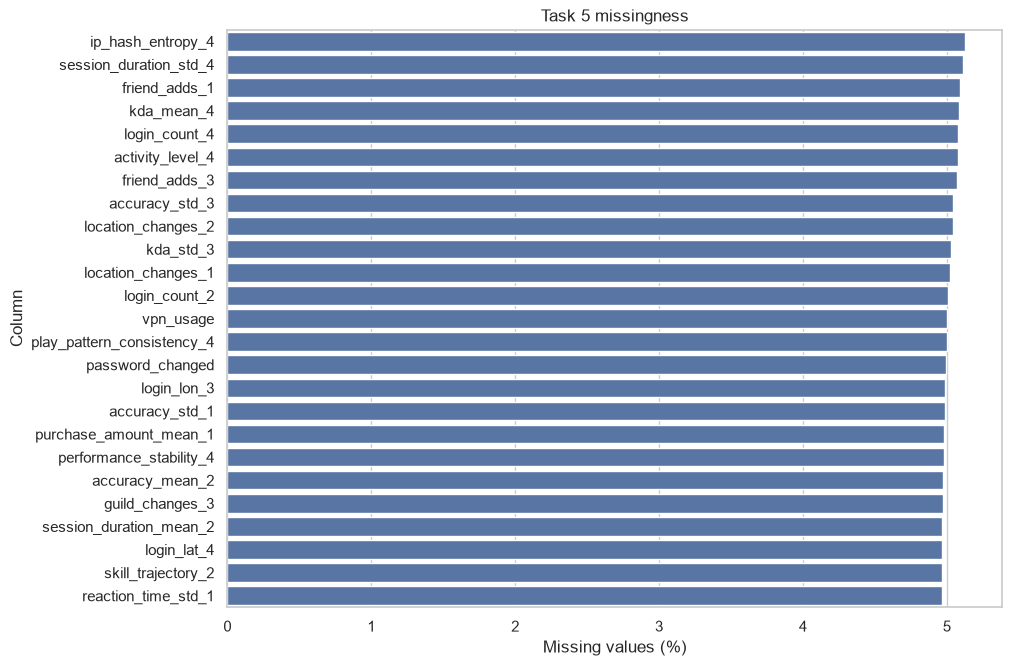

In [7]:
display(df.dtypes.rename('dtype').to_frame())
display(df.nunique(dropna=False).rename('unique_values').to_frame().sort_values('unique_values'))
missing=quality_report(df)
plot_missing(missing, 'Task 5 missingness')

## 3. Feature Distribution Analysis

Repeated four-period bases: ['accuracy_mean', 'accuracy_std', 'activity_level', 'communication_frequency', 'currency_transfers', 'device_count', 'friend_adds', 'friend_removes', 'guild_changes', 'ip_hash_entropy', 'kda_mean', 'kda_std', 'location_changes', 'login_count', 'login_lat', 'login_lon', 'login_time_variance', 'performance_stability', 'play_pattern_consistency', 'purchase_amount_mean', 'purchase_amount_std', 'purchase_frequency', 'reaction_time_mean', 'reaction_time_std', 'refund_count', 'session_duration_mean', 'session_duration_std', 'skill_rating', 'skill_trajectory']


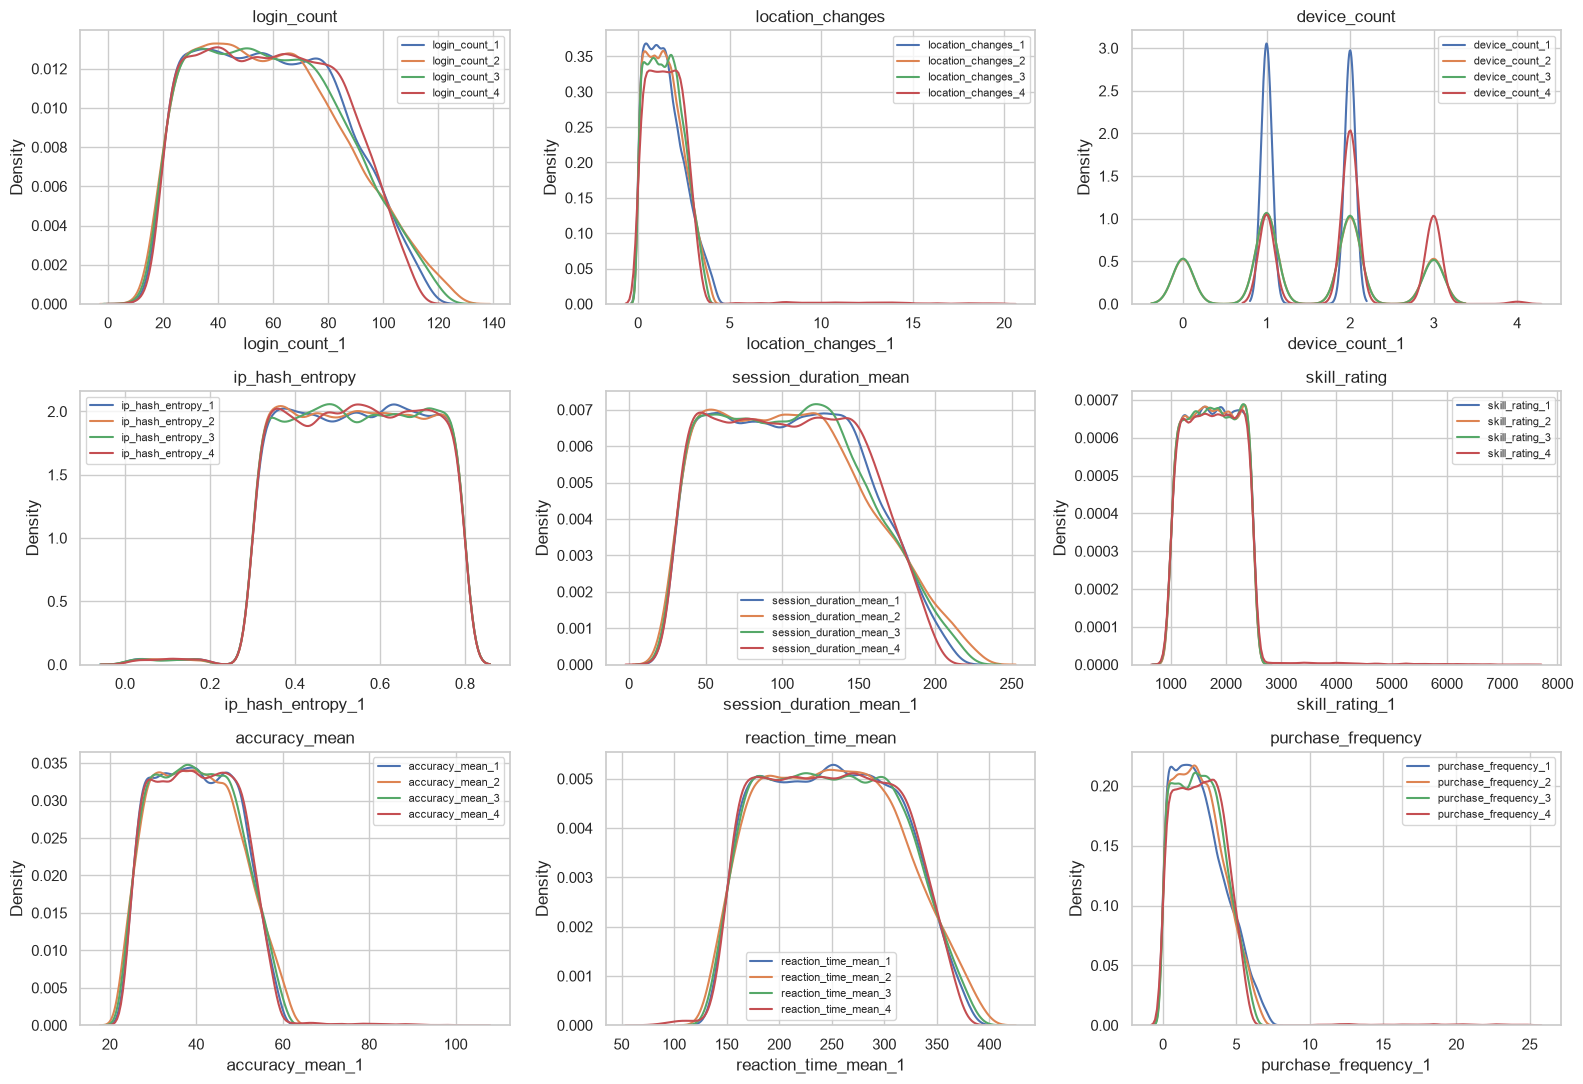

In [8]:
base_features = sorted({c.rsplit('_',1)[0] for c in df.columns if c.rsplit('_',1)[-1] in {'1','2','3','4'}})
print('Repeated four-period bases:', base_features)
selected=['login_count','location_changes','device_count','ip_hash_entropy','session_duration_mean','skill_rating','accuracy_mean','reaction_time_mean','purchase_frequency']
fig,axes=plt.subplots(3,3,figsize=(16,11)); axes=axes.ravel()
for ax,base in zip(axes,selected):
    cols=[f'{base}_{i}' for i in range(1,5) if f'{base}_{i}' in df]
    for col in cols: sns.kdeplot(df[col].dropna(), ax=ax, label=col, warn_singular=False)
    ax.set_title(base); ax.legend(fontsize=8)
plt.tight_layout(); plt.show(); plt.close()

## 4. Feature Relationships

,level_0,level_1,correlation
617,login_lon_1,login_lon_2,0.999977
494,login_lat_1,login_lat_2,0.999791
863,login_lon_2,login_lon_3,0.999562
619,login_lon_1,login_lon_3,0.999550
496,login_lat_1,login_lat_3,0.997993
740,login_lat_2,login_lat_3,0.997975
865,login_lon_2,login_lon_4,0.996654
621,login_lon_1,login_lon_4,0.996597
1109,login_lon_3,login_lon_4,0.996239
4430,skill_rating_1,skill_rating_3,0.986596


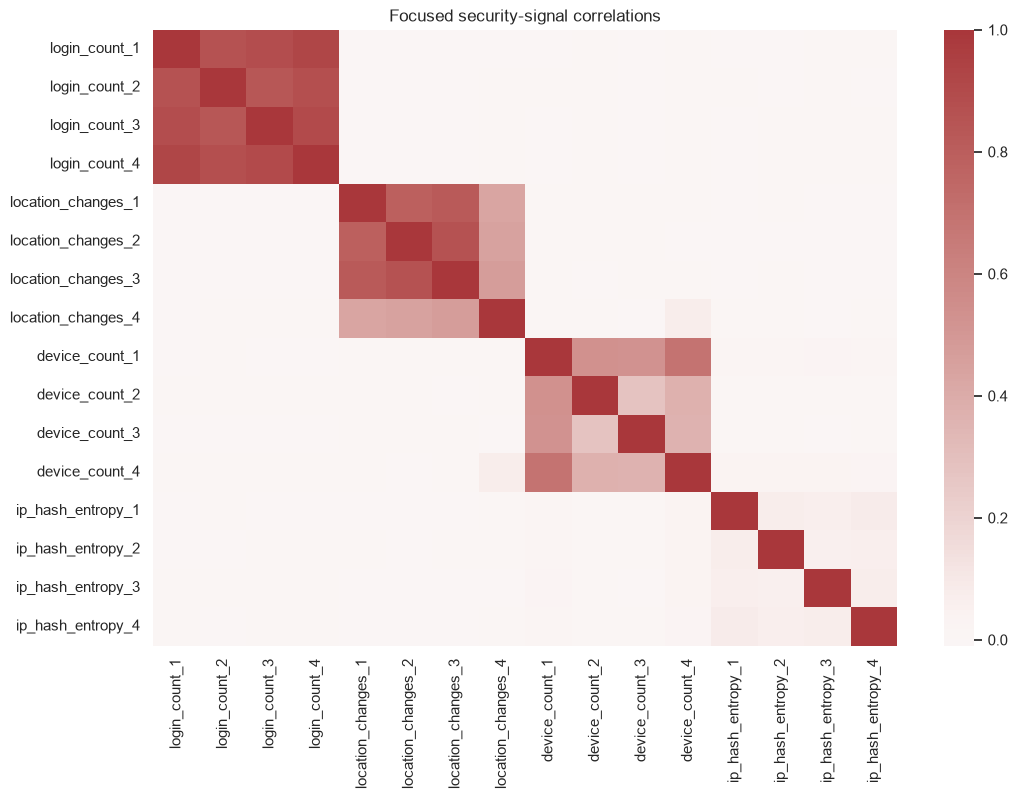

In [9]:
corr=df.drop(columns='player_id').corr(numeric_only=True)
pairs=strong_correlations(df.drop(columns='player_id'), threshold=.80)
display(pairs.head(40))
# A focused, readable view of repeated login and device signals.
focus=[c for c in df.columns if any(c.startswith(x) for x in ['login_count_','device_count_','location_changes_','ip_hash_entropy_'])]
plt.figure(figsize=(12,8)); sns.heatmap(df[focus].corr(), cmap='vlag', center=0); plt.title('Focused security-signal correlations'); plt.show(); plt.close()

## 5. Unsupervised Behavioral Analysis

In [10]:
# Per-row changes are descriptive engineered candidates; df itself is unchanged.
for base in base_features:
    cols=[f'{base}_{i}' for i in range(1,5)]
    if all(c in df for c in cols):
        values=df[cols]
        change=values.iloc[:,-1]-values.iloc[:,0]
        variability=values.std(axis=1)
        print(f'{base}: period-4 minus period-1 median={change.median():.3f}; within-row SD median={variability.median():.3f}')

def haversine_km(lat1, lon1, lat2, lon2):
    lat1,lon1,lat2,lon2=np.radians([lat1,lon1,lat2,lon2])
    a=np.sin((lat2-lat1)/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371*2*np.arcsin(np.sqrt(a))
for i in range(1,4):
    needed=[f'login_lat_{i}',f'login_lon_{i}',f'login_lat_{i+1}',f'login_lon_{i+1}']
    if all(c in df for c in needed):
        distance=haversine_km(*(df[c] for c in needed))
        print(f'Login distance {i}→{i+1} (km): median={np.nanmedian(distance):.2f}, p99={np.nanquantile(distance,.99):.2f}, max={np.nanmax(distance):.2f}')
print('These descriptive extremes are potential review signals, not anomaly labels.')

accuracy_mean: period-4 minus period-1 median=0.057; within-row SD median=2.405
accuracy_std: period-4 minus period-1 median=0.011; within-row SD median=0.752
activity_level: period-4 minus period-1 median=-0.001; within-row SD median=0.116
communication_frequency: period-4 minus period-1 median=0.001; within-row SD median=0.086
currency_transfers: period-4 minus period-1 median=0.009; within-row SD median=0.704
device_count: period-4 minus period-1 median=1.000; within-row SD median=0.577
friend_adds: period-4 minus period-1 median=0.000; within-row SD median=1.669
friend_removes: period-4 minus period-1 median=0.000; within-row SD median=0.340
guild_changes: period-4 minus period-1 median=1.000; within-row SD median=0.577
ip_hash_entropy: period-4 minus period-1 median=0.001; within-row SD median=0.137
kda_mean: period-4 minus period-1 median=0.003; within-row SD median=0.248
kda_std: period-4 minus period-1 median=-0.000; within-row SD median=0.057
location_changes: period-4 minus p

## 6. EDA Summary & Recommendations

### Key findings

- The supplied unlabeled file has 25,889 rows and 123 columns: player_id plus 122 behavioural variables.
- It contains no duplicate rows, duplicate player_id values, or infinite numeric values.
- Missingness is present: ip_hash_entropy_4 has 1,328 missing values, session_duration_std_4 has 1,324, and friend_adds_1 has 1,319.
- The repeated four-period structure supports descriptive candidate features: period deltas, within-player variability, relative login-count change, device-count change, and maximum or mean Haversine movement.
- Extreme values and unusual combinations are descriptive review signals, not anomaly labels.

### Recommendations and project-rule ambiguity

Validate coordinate ranges and compute geographic movement only for complete coordinate pairs. Scale heterogeneous future features and handle missingness without fitting preprocessing on hidden labels. The project provides only an unlabeled file and calls the task unsupervised, but also restricts use of test data for training. Whether this file may be used to fit a future unsupervised detector requires instructor clarification; this notebook does not fit a model or preprocessing parameter.
